### Project Overview

This project aims to analyze a real-world dataset obtained from Kaggle, containing information about students and their stress levels.

The main objective is to identify factors that contribute to student stress and provide **data-driven insights** to help educational institutions better understand and support their students.

Through this analysis, educational institutions can develop more effective strategies to improve **student well-being, academic performance, and the overall quality of education**.



# 1. Problem Statement & Dataset Description

Stress is one of the major factors that can affect students' learning quality and academic performance. To help students manage stress effectively, it is important to understand relevant factors, such as their learning environment, academic pressures, and personal habits.

This project focuses on the problem statement: **"Analysis of Academic Stress Levels Across Different Academic Stages."**

The dataset was obtained from **Kaggle** (https://www.kaggle.com/datasets/poushal02/student-academic-stress-real-world-dataset?resource=download) and contains information collected from students across different academic stages, including high school, undergraduate, and postgraduate levels.

To address this problem, several statistical analyses and data visualization techniques will be conducted to identify patterns, relationships, and potential differences in student stress levels.

#### Data Visualization

1. How are students distributed across different academic stress levels?
2. How does the average stress index differ across academic stages?
3. What is the relationship between **academic pressure from home** and the **stress index** at each academic stage?
4. What is the relationship between **academic competition** and the **stress index** at each academic stage?

#### Descriptive Statistics

1. What are the overall characteristics of the stress index across different academic stress levels?

#### Inferential Statistics

1. Is there a **statistically significant difference** in the mean stress index among high school, undergraduate, and postgraduate students?



# 2. Data Loading

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_dataset.csv")

df.head()

,Timestamp,Your Academic Stage,Peer pressure,Academic pressure from your home,Study Environment,What coping strategy you use as a student?,"Do you have any bad habits like smoking, drinking on a daily basis?",What would you rate the academic competition in your student life,Rate your academic stress index
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Analyze the situation and handle it with intel...,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Analyze the situation and handle it with intel...,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,"Social support (friends, family)",No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,5


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    shapiro,
    levene,
    f_oneway,
    kruskal,
    spearmanr
)

from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 3. Data Cleaning

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 9 columns):
 #   Column                                                               Non-Null Count  Dtype 
---  ------                                                               --------------  ----- 
 0   Timestamp                                                            140 non-null    object
 1   Your Academic Stage                                                  140 non-null    object
 2   Peer pressure                                                        140 non-null    int64 
 3   Academic pressure from your home                                     140 non-null    int64 
 4   Study Environment                                                    139 non-null    object
 5   What coping strategy you use as a student?                           140 non-null    object
 6   Do you have any bad habits like smoking, drinking on a daily basis?  140 non-null    object
 7   What would you rat

Checking all data

In [4]:
df.columns = [
    "timestamp",
    "academic_stage",
    "peer_pressure",
    "academic_pressure_home",
    "study_environment",
    "coping_strategy",
    "bad_habits",
    "academic_competition",
    "stress_index"
]

df.head()

,timestamp,academic_stage,peer_pressure,academic_pressure_home,study_environment,coping_strategy,bad_habits,academic_competition,stress_index
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Analyze the situation and handle it with intel...,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Analyze the situation and handle it with intel...,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,"Social support (friends, family)",No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,5


Changing column names

In [5]:
missing_values = pd.DataFrame({
    "missing_value": df.isnull().sum(),
    "percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values

,missing_value,percentage
timestamp,0,0.00
academic_stage,0,0.00
peer_pressure,0,0.00
academic_pressure_home,0,0.00
study_environment,1,0.71
coping_strategy,0,0.00
bad_habits,0,0.00
academic_competition,0,0.00
stress_index,0,0.00


In [6]:
df["study_environment"].value_counts()

study_environment
Peaceful     69
disrupted    38
Noisy        32
Name: count, dtype: int64

In [7]:
df["study_environment"] = df["study_environment"].fillna(
    df["study_environment"].mode()[0]
)

In [8]:
missing_values = pd.DataFrame({
    "missing_value": df.isnull().sum(),
    "percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values

,missing_value,percentage
timestamp,0,0.0
academic_stage,0,0.0
peer_pressure,0,0.0
academic_pressure_home,0,0.0
study_environment,0,0.0
coping_strategy,0,0.0
bad_habits,0,0.0
academic_competition,0,0.0
stress_index,0,0.0


Checking missing values and handling using mode values

In [9]:
print("Jumlah duplicate:", df.duplicated().sum())

Jumlah duplicate: 0


Check duplicates

In [10]:
df.dtypes

timestamp                 object
academic_stage            object
peer_pressure              int64
academic_pressure_home     int64
study_environment         object
coping_strategy           object
bad_habits                object
academic_competition       int64
stress_index               int64
dtype: object

In [11]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

/var/folders/xb/rzkrcq9x41l2k4hkkp4s_8qr0000gn/T/ipykernel_6759/2590017084.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["timestamp"] = pd.to_datetime(


Check data type and change timestamp to datetime

In [12]:
categorical_columns = [
    "academic_stage",
    "study_environment",
    "coping_strategy",
    "bad_habits"
]

for col in categorical_columns:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False))


=== academic_stage ===
academic_stage
undergraduate    100
high school       29
post-graduate     11
Name: count, dtype: int64

=== study_environment ===
study_environment
Peaceful     70
disrupted    38
Noisy        32
Name: count, dtype: int64

=== coping_strategy ===
coping_strategy
Analyze the situation and handle it with intellect    87
Emotional breakdown (crying a lot)                    32
Social support (friends, family)                      21
Name: count, dtype: int64

=== bad_habits ===
bad_habits
No                   123
Yes                   10
prefer not to say      7
Name: count, dtype: int64


In [13]:
numeric_columns = [
    "peer_pressure",
    "academic_pressure_home",
    "academic_competition",
    "stress_index"
]

for col in numeric_columns:
    print(f"\n=== {col} ===")
    print(sorted(df[col].dropna().unique()))


=== peer_pressure ===
[1, 2, 3, 4, 5]

=== academic_pressure_home ===
[1, 2, 3, 4, 5]

=== academic_competition ===
[1, 2, 3, 4, 5]

=== stress_index ===
[1, 2, 3, 4, 5]


In [14]:
print("Shape:", df.shape)

df.info()

Shape: (140, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   timestamp               140 non-null    datetime64[ns]
 1   academic_stage          140 non-null    object        
 2   peer_pressure           140 non-null    int64         
 3   academic_pressure_home  140 non-null    int64         
 4   study_environment       140 non-null    object        
 5   coping_strategy         140 non-null    object        
 6   bad_habits              140 non-null    object        
 7   academic_competition    140 non-null    int64         
 8   stress_index            140 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 10.0+ KB


In [ ]:
df.to_csv("student_dataset_cleaned.csv" , index=False)

save cleaned dataset

# 4. Exploration & Analysis

## Data Visualization

### 1. What is the distribution of students across different academic stress levels?


In [ ]:
stage_count = (
    df["academic_stage"]
    .value_counts()
    .reset_index()
)

stage_count.columns = ["academic_stage", "count"]

stage_count

,academic_stage,count
0,undergraduate,100
1,high school,29
2,post-graduate,11


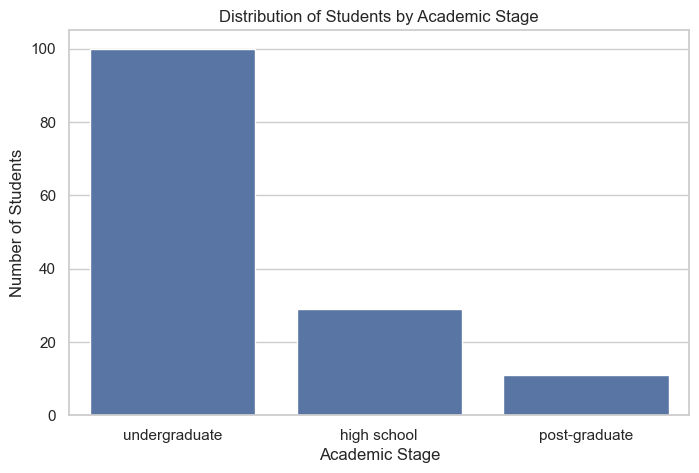

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="academic_stage",
    order=df["academic_stage"].value_counts().index
)

plt.title("Distribution of Students by Academic Stage")
plt.xlabel("Academic Stage")
plt.ylabel("Number of Students")

plt.show()

##### Analysis

The majority of students in the dataset are **undergraduates**, with approximately 100 students, followed by **high school students** with around 30 students and **postgraduate students** with approximately 10 students.

This indicates that the dataset is heavily dominated by undergraduate students. Therefore, comparisons across academic stages should consider the **unequal distribution of observations**, as the imbalance may affect the interpretation and reliability of the results.


### 2. How does the average stress index differ across academic stages?


In [17]:
stress_distribution = (
    df["stress_index"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

stress_distribution

stress_index
1     4.29
2     6.43
3    25.71
4    40.00
5    23.57
Name: proportion, dtype: float64

In [24]:
stress_stage = (
    df.groupby("academic_stage")["stress_index"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .sort_values("mean", ascending=False)
)

stress_stage

,count,mean,median,std
academic_stage,,,,
high school,29,3.827586,4.0,1.136064
post-graduate,11,3.727273,4.0,0.646670
undergraduate,100,3.690000,4.0,1.041512


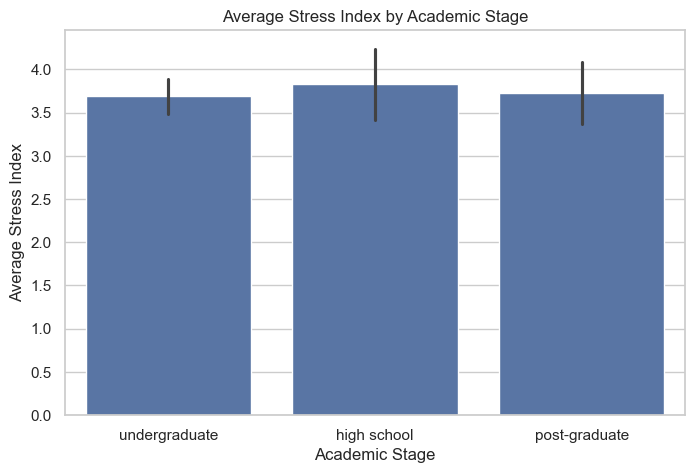

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="academic_stage",
    y="stress_index",
    errorbar="ci"
)

plt.title("Average Stress Index by Academic Stage")
plt.xlabel("Academic Stage")
plt.ylabel("Average Stress Index")

plt.show()

##### Analysis

**High school students** have the highest average Stress Index at approximately **3.8**, followed by **postgraduate and undergraduate students**, both with an average of around **3.7**.

Although the differences are relatively small, high school students demonstrate the **highest average stress level** compared to other academic stages.


### 3. What is the relationship between academic pressure from home and the stress index across different academic stages?


In [ ]:
pressure_home = (
    df.groupby(
        ["academic_stage", "academic_pressure_home"]
    )["stress_index"]
    .mean()Bagaimana hubungan akademik presssure from home dengan sress index pada masing masing akademik stage?


    .reset_index()
)

pressure_home

,academic_stage,academic_pressure_home,stress_index
0,high school,1,2.500000
1,high school,2,3.500000
2,high school,3,3.600000
3,high school,4,3.625000
4,high school,5,4.857143
5,post-graduate,1,5.000000
6,post-graduate,2,4.000000
7,post-graduate,3,3.500000
8,post-graduate,4,3.750000
9,post-graduate,5,3.000000


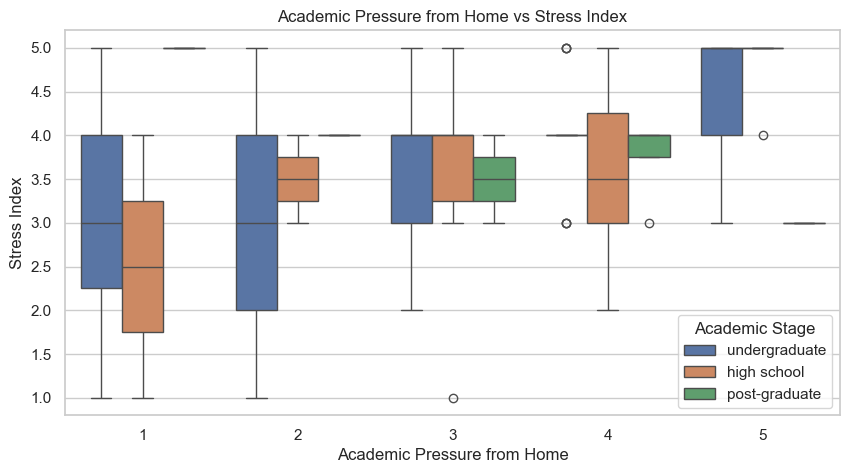

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="academic_pressure_home",
    y="stress_index",
    hue="academic_stage"
)

plt.title(
    "Academic Pressure from Home vs Stress Index"
)

plt.xlabel("Academic Pressure from Home")
plt.ylabel("Stress Index")

plt.legend(title="Academic Stage")

plt.show()

##### Analysis

In general, as **Academic Pressure from Home increases, the Stress Index tends to increase as well**.

At higher academic pressure levels (4–5), several groups show a **Stress Index of approximately 4–5**, while students experiencing lower academic pressure (level 1) tend to have lower stress levels.

These findings suggest a **positive relationship between academic pressure from home and student stress levels** across different academic stages.


### 4. What is the relationship between academic competition and the stress index across different academic stages?


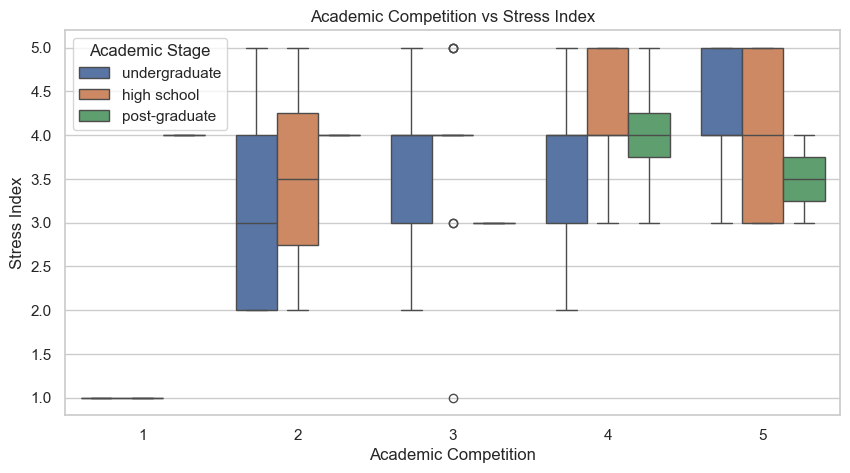

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="academic_competition",
    y="stress_index",
    hue="academic_stage"
)

plt.title(
    "Academic Competition vs Stress Index"
)

plt.xlabel("Academic Competition")
plt.ylabel("Stress Index")

plt.legend(title="Academic Stage")

plt.show()

##### Analysis

Students with higher levels of **Academic Competition** tend to have a higher **Stress Index**.

At higher competition levels (4–5), the Stress Index frequently ranges between **4 and 5**, while students experiencing lower competition levels (1–2) generally demonstrate lower stress levels.

These findings suggest a **positive relationship between academic competition and student stress levels**, indicating that increased academic competition tends to be associated with higher academic stress.


## Descriptive Statistic

### 1. Central Tendency – What are the overall characteristics of the Stress Index across different academic stress levels?


In [34]:
descriptive = df.groupby("academic_stage")["stress_index"].agg(
    count="count",
    mean="mean",
    median="median"
)

descriptive




,count,mean,median
academic_stage,,,
high school,29,3.827586,4.0
post-graduate,11,3.727273,4.0
undergraduate,100,3.690000,4.0


In [35]:
mode_stress = (
    df.groupby("academic_stage")["stress_index"]
    .agg(lambda x: x.mode().iloc[0])
)

mode_stress

academic_stage
high school      4
post-graduate    4
undergraduate    4
Name: stress_index, dtype: int64

##### Analysis

**High school students** have the highest average Stress Index (**3.83**), while **undergraduate students** have the lowest average (**3.69**).

However, the **median and mode are both 4 across all academic stages**, indicating that a Stress Index of 4 is the most common and typical stress level among students, regardless of their academic stage.


## Inferential Statistic

### 1. Is there a statistically significant difference in the mean Stress Index among high school, undergraduate, and postgraduate students?

#### One-Way ANOVA


In [40]:
anova_stat, anova_p = f_oneway(*groups)

print("F-statistic :", anova_stat)
print("P-value     :", anova_p)

F-statistic : 0.19754015838240996
P-value     : 0.820980540624812


In [ ]:
alpha = 0.05

if anova_p < alpha:
    print("Reject H0")
    
else:
    print("Fail to Reject H0")
    


Fail to Reject H0
Tidak terdapat cukup bukti bahwa rata-rata Stress Index berbeda antar Academic Stage.


##### Analysis

The **One-Way ANOVA** results show an **F-statistic of 0.198** and a **p-value of 0.821 (> 0.05)**.

Since the p-value exceeds the significance level of 0.05, we **fail to reject the null hypothesis (H₀)**. This indicates that there is insufficient statistical evidence to conclude that the mean Stress Index differs significantly across academic stages.

Although **high school students have the highest average Stress Index** based on descriptive statistics, the differences among high school, undergraduate, and postgraduate students are **not statistically significant**.


To further investigate the relationships between the Stress Index and its contributing factors, **Spearman's Rank Correlation Test** is used to measure the strength and direction of these relationships.


In [42]:
factors = [
    "peer_pressure",
    "academic_pressure_home",
    "academic_competition"
]

correlation_results = []

for factor in factors:
    
    rho, p_value = spearmanr(
        df[factor],
        df["stress_index"]
    )
    
    correlation_results.append({
        "factor": factor,
        "spearman_rho": rho,
        "p_value": p_value
    })

correlation_df = pd.DataFrame(correlation_results)

correlation_df

,factor,spearman_rho,p_value
0,peer_pressure,0.453209,1.879125e-08
1,academic_pressure_home,0.390477,1.846865e-06
2,academic_competition,0.335886,4.967867e-05


In [44]:
results = []

for stage, group in df.groupby("academic_stage"):
    
    for factor in factors:
        
        rho, p_value = spearmanr(
            group[factor],
            group["stress_index"]
        )
        
        results.append({
            "academic_stage": stage,
            "factor": factor,
            "spearman_rho": rho,
            "p_value": p_value
        })

stage_correlation = pd.DataFrame(results)

stage_correlation

,academic_stage,factor,spearman_rho,p_value
0,high school,peer_pressure,0.688997,0.000036
1,high school,academic_pressure_home,0.533303,0.002892
2,high school,academic_competition,0.183222,0.341418
3,post-graduate,peer_pressure,0.092710,0.786303
4,post-graduate,academic_pressure_home,-0.656759,0.028144
5,post-graduate,academic_competition,-0.102454,0.764363
6,undergraduate,peer_pressure,0.409272,0.000024
7,undergraduate,academic_pressure_home,0.440480,0.000005
8,undergraduate,academic_competition,0.426210,0.000010


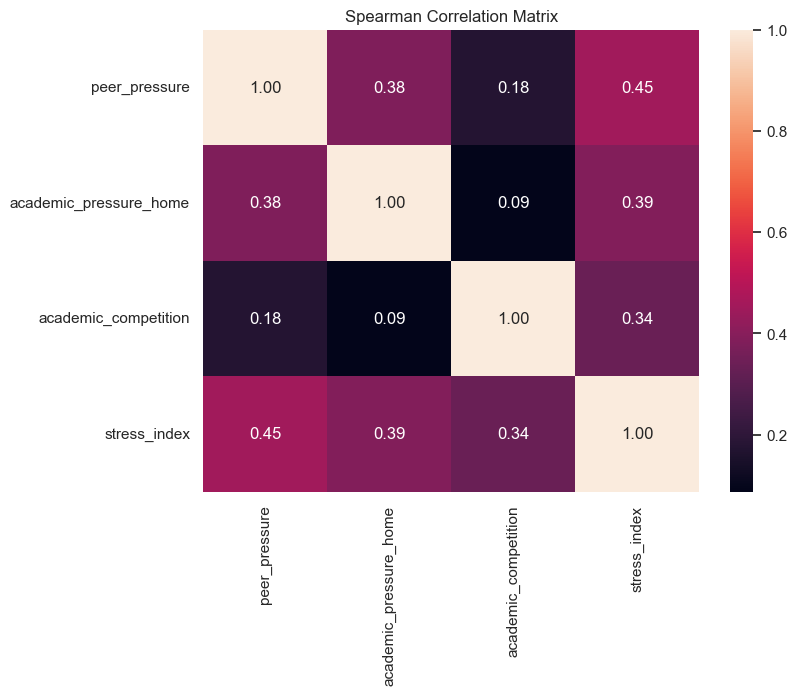

In [45]:
correlation_matrix = df[
    [
        "peer_pressure",
        "academic_pressure_home",
        "academic_competition",
        "stress_index"
    ]
].corr(method="spearman")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Spearman Correlation Matrix")

plt.show()

##### Analysis

The results indicate that there is **no statistically significant difference in the mean Stress Index across Academic Stages** (p-value = 0.821).

However, **Spearman's Rank Correlation Analysis** reveals that **Peer Pressure, Academic Pressure from Home, and Academic Competition** have positive and statistically significant correlations with the Stress Index overall.

- **Peer Pressure** shows the strongest overall correlation with the Stress Index (**ρ = 0.453**), indicating a moderate positive relationship.
- **High School:** Peer Pressure has the strongest correlation with the Stress Index compared to the other factors.
- **Undergraduate:** All three factors demonstrate positive and statistically significant correlations with the Stress Index.
- **Postgraduate:** Only Academic Pressure from Home shows a statistically significant correlation with the Stress Index, and the relationship is negative.

However, the postgraduate findings should be **interpreted with caution**, as this group contains only **11 students**, which may limit the reliability and generalizability of the results.

**Overall Conclusion:** Although academic stage itself does not show a statistically significant difference in average stress levels, **academic and social pressures are significantly associated with student stress**. These findings suggest that educational institutions should consider the different stress-related factors experienced by students at each academic stage when developing student support strategies.


# 5. Conclusion

Based on the overall analysis, **high school students have the highest average Stress Index (3.83)**. However, the differences in mean stress levels across academic stages are **not statistically significant**.

Overall, **Peer Pressure, Academic Pressure from Home, and Academic Competition** show positive and statistically significant correlations with the Stress Index, with **Peer Pressure demonstrating the strongest correlation (ρ = 0.453)**.

### Recommendations

Educational institutions should focus on **reducing social and academic pressures**, particularly **Peer Pressure**, as it shows the strongest association with student stress levels.

Implementing student support programs, peer counseling, and stress management initiatives may help create a healthier learning environment and improve overall student well-being.


Tableau link : https://public.tableau.com/app/profile/amanda.amalia.putriprayogi/viz/P0M1_Amanda_Amalia/Dashboard1?publish=yes